# Quickstart: NOAA RTMA, RTMA-RU and URMA analyses, virtual - dynamical.org Icechunk Zarr

[NOAA's RTMA family](https://emc.ncep.noaa.gov/emc/pages/numerical_forecast_systems/rtma.php) combines observations with a model background on a 2.5 km CONUS grid. RTMA and RTMA-RU emphasize timely situational awareness; URMA admits later observations for verification and calibration. All three apply observation quality control.

| Product | Cadence and upstream timing | Virtual archive starts |
| --- | --- | --- |
| RTMA | Hourly; about 55 minutes after valid time | 2017-05-02 |
| RTMA-RU | Every 15 minutes; about 15–20 minutes after valid time | 2017-12-13 |
| URMA | Hourly; runs six hours later to include late observations | 2017-05-02; wave height from 2018-12-03 12:00 UTC |

Only hourly RTMA is available in the selected catalog today. RU and URMA examples follow at launch. These virtual products exclude precipitation; upstream timings are not archive delivery guarantees.

Dataset documentation:
- RTMA: https://dynamical.org/catalog/noaa-rtma-analysis-virtual/


In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install dynamical-catalog cartopy rioxarray pyproj matplotlib

In [2]:
import dynamical_catalog

In [3]:
rtma = dynamical_catalog.open("noaa-rtma-analysis-virtual", chunks=None)
rtma

<xarray.Dataset> Size: 32TB
Dimensions:                       (time: 83064, y: 1597, x: 2345)
Coordinates:
  * time                          (time) datetime64[ns] 665kB 2017-05-02 ... ...
  * y                             (y) float64 13kB 3.79e+06 ... -2.638e+05
  * x                             (x) float64 19kB -3.271e+06 ... 2.682e+06
    longitude                     (y, x) float32 15MB ...
    latitude                      (y, x) float32 15MB ...
    spatial_ref                   int64 8B ...
Data variables: (12/13)
    cloud_ceiling_height          (time, y, x) float64 2TB ...
    dew_point_temperature_2m      (time, y, x) float64 2TB ...
    pressure_surface              (time, y, x) float64 2TB ...
    specific_humidity_2m          (time, y, x) float64 2TB ...
    geopotential_height_surface   (time, y, x) float64 2TB ...
    temperature_2m                (time, y, x) float64 2TB ...
    ...                            ...
    visibility_surface            (time, y, x) float64 2TB ...
    wind_speed_10m                (time, y, x) float64 2TB ...
    wind_u_10m                    (time, y, x) float64 2TB ...
    wind_v_10m                    (time, y, x) float64 2TB ...
    wind_gust_10m                 (time, y, x) float64 2TB ...
    wind_direction_10m            (time, y, x) float64 2TB ...
Attributes:
    dataset_id:          noaa-rtma-analysis-virtual
    dataset_version:     0.1.0
    name:                NOAA RTMA analysis, virtual
    description:         Hourly Real-Time Mesoscale Analysis (RTMA) operated ...
    attribution:         NOAA NWS NCEP RTMA data processed by dynamical.org f...
    license:             CC-BY-4.0
    spatial_domain:      Continental United States
    spatial_resolution:  2.5 km
    time_domain:         2017-05-02 00:00:00 UTC to Present
    time_resolution:     1 hour

## How did the Northwest heat wave unfold?

The Pacific Northwest experienced [record heat in late June 2021](https://www.ncei.noaa.gov/news/national-climate-202106). These are hourly analyzed temperatures at the grid cell nearest Seattle, not station observations. All times are UTC.


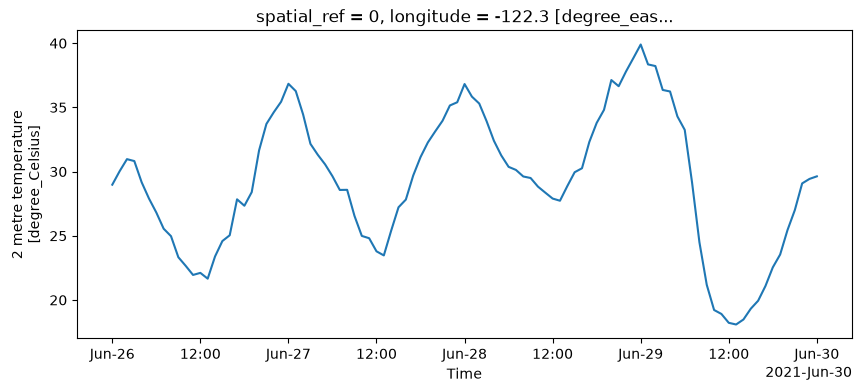

In [4]:
import rioxarray  # noqa: F401  enables the .rio accessor
from pyproj import Transformer

lon_lat_to_grid = Transformer.from_crs("EPSG:4326", rtma.rio.crs, always_xy=True)
seattle_x, seattle_y = lon_lat_to_grid.transform(-122.33, 47.61)

(
    rtma["temperature_2m"]
    .sel(time=slice("2021-06-26T00", "2021-06-30T00"))
    .sel(x=seattle_x, y=seattle_y, method="nearest")
    .plot(size=4, aspect=2.5)
)

## How did the downslope winds evolve during the Marshall Fire?

[Strong winds fanned the Marshall Fire on 30 December 2021](https://www.weather.gov/bou/HighWinds12_30_2021), with some of the strongest winds around noon Mountain time (19 UTC). Follow analyzed 10 m wind speed from 16 to 23 UTC across the Front Range. This shows the near-surface wind field, not fire spread or peak gusts.


In [5]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
import numpy as np

grid = rtma.spatial_ref.attrs
rtma_proj = ccrs.LambertConformal(
    central_longitude=grid["longitude_of_central_meridian"],
    central_latitude=grid["latitude_of_projection_origin"],
    standard_parallels=tuple(np.atleast_1d(grid["standard_parallel"])),
    globe=ccrs.Globe(
        semimajor_axis=grid["semi_major_axis"],
        semiminor_axis=grid["semi_minor_axis"],
    ),
)

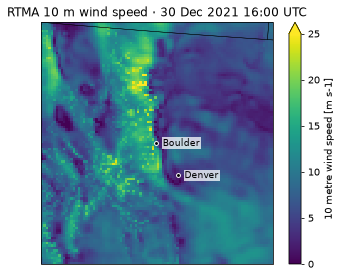

In [6]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

wind = (
    rtma["wind_speed_10m"]
    .sel(time=slice("2021-12-30T16", "2021-12-30T23"))
    .rio.clip_box(-106.5, 39, -104, 41, crs="EPSG:4326")
    .load()
)

fig, ax = plt.subplots(figsize=(6, 4.5), dpi=70, subplot_kw={"projection": rtma_proj})
image = wind.isel(time=0).plot(
    ax=ax,
    transform=rtma_proj,
    cmap="viridis",
    vmin=0,
    vmax=25,
    center=False,
)
ax.add_feature(cfeature.STATES, linewidth=0.4)
for city, longitude, latitude in [
    ("Denver", -104.9903, 39.7392),
    ("Boulder", -105.2705, 40.0150),
]:
    ax.plot(
        longitude,
        latitude,
        "o",
        transform=ccrs.PlateCarree(),
        markersize=4,
        color="black",
        markeredgecolor="white",
        zorder=3,
    )
    ax.text(
        longitude + 0.08,
        latitude,
        city,
        transform=ccrs.PlateCarree(),
        fontsize=9,
        va="center",
        zorder=3,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.75, "pad": 1},
    )
ax.set_title("RTMA 10 m wind speed · 30 Dec 2021 16:00 UTC")


def draw_frame(i: int) -> None:
    frame = wind.isel(time=i)
    image.set_array(frame.values.ravel())
    ax.set_title(
        f"RTMA 10 m wind speed · {frame.time.dt.strftime('%d %b %Y %H:%M UTC').item()}"
    )


anim = FuncAnimation(fig, draw_frame, frames=wind.sizes["time"], interval=450)
HTML(anim.to_jshtml())

Ceiling and visibility retain raw finite source values, including bounds that changed over time; the archive asserts no ceiling datum. Consult the [validation report](https://dataset-validation-reports.dynamical.org/noaa-rtma-analysis-virtual/latest/validation_report.html) before using those fields for thresholds or trends.


## RTMA-RU: what changes between hourly wind analyses? — launch pending

The [15 December 2021 Plains wind event](https://www.weather.gov/ict/event_2021Dec15thWindFireSVR) offers a case for comparing quarter-hour RU with hourly RTMA near Wichita. At launch, examine 18–00 UTC for changes between hourly samples; RU provides new analyses, not interpolated RTMA values.


## URMA: how did wave height vary across Lake Erie? — launch pending

[Storm-force winds crossed Lake Erie on 23 December 2022](https://www.weather.gov/cle/event_Christmas_Blizzard_2022). At launch, examine URMA's significant wave height across the lake. NaN denotes places without a wave analysis, including land and ice-covered water; it is not zero wave height.


## Community challenge

- How did coastal and inland temperatures evolve during the June 2021 heat wave? Which comparison stations contributed observations to the analysis?
- Once RU launches, which short wind changes during the December 2021 event are undersampled by hourly RTMA, and do surface reports support them?
- Once URMA launches, where does it differ most from RTMA at matching times, and do independent observations support those differences?
